# Parameter and Constant

Physical models are full of numbers: a mass, a stiffness, a gravity, a gain.
Some are known, some are guesses to be refined from data. *nnodely* has a
stream for each:

- a `Constant` holds a value the model uses as it is;
- a `Parameter` holds a value that **training learns**, starting from a guess or
  from a random draw.

Both are streams like any other: combined with operators and layers, with a
shape declared as an input's. This tutorial shows:

- how to declare them, and how their value fills the shape `(S*, T, D*)`;
- how they combine with signals: one value for every sample, or one per sample
  of a window, per feature, per step;
- how a physical constant is identified from data;
- freezing, reading and sharing their values.

In [1]:
import os

# Pick the Keras backend before nnodely (or Keras) is imported:
# "tensorflow" (the default), "torch" or "jax".
os.environ.setdefault("KERAS_BACKEND", "tensorflow")

import keras
import matplotlib.pyplot as plt
import numpy as np

from nnodely import (
    Constant,
    DataLoader,
    Input,
    Modely,
    Output,
    Parameter,
    TimeSelect,
    set_seed,
)

set_seed(0)

## Declaring them

A `Constant` needs a `value`. A `Parameter` takes one as its initial value, or
is drawn by an `initializer` (a Keras initializer, `"random_normal"` by
default). A number written in an expression, `2.0 * x`, becomes a `Constant` by
itself.

In [2]:
g = Constant("g", value=9.81)
mass = Parameter("mass", value=1.5)  # a guess, refined by training
gains = Parameter("gains", value=[1.0, 0.5, 0.25])  # three values
noise = Parameter("noise", dim=4)  # four values, drawn at random
zeros = Parameter("bias", dim=2, initializer="zeros")

for value in (g, mass, gains, noise, zeros):
    shown = (
        "drawn by the initializer at build"
        if value.value is None
        else value.value.round(3).tolist()
    )
    print(f"{value.name:6s} {str(value.shape):28s} {shown}")

try:
    Constant("unknown")  # a Constant needs its value
except TypeError as error:
    print("TypeError:", error)

g      Shape(S=(), T=None, D=(1,))  [9.8100004196167]
mass   Shape(S=(), T=None, D=(1,))  [1.5]
gains  Shape(S=(), T=None, D=(3,))  [1.0, 0.5, 0.25]
noise  Shape(S=(), T=None, D=(4,))  drawn by the initializer at build
bias   Shape(S=(), T=None, D=(2,))  drawn by the initializer at build
TypeError: Constant.__init__() missing 1 required keyword-only argument: 'value'


Declared without a window (`T=None`), a value applies to **every sample** of
the streams it is combined with, at every step - like a number does.

## The shape of a value

`seq`, `tw` and `dim` are declared as for an `Input` - sizes, laid out
`(S*, T, D*)` - and the value fills them:

- a **flat list** (or a number) holds exactly `prod(seq) * tw * prod(dim)`
  values, read row-major;
- an **array of several axes** has the declared sizes, in any order: its axes
  are moved into place;
- with a value and **no** `dim`, `seq` and `tw` take the axes of their sizes, and
  the axes left over are the dims, in their order.

In [3]:
flat = Parameter("flat", value=[1, 2, 3, 4, 5, 6], tw=2, dim=3)
print(flat.shape)
print(flat.value)

Shape(S=(), T=2, D=(3,))
[[1. 2. 3.]
 [4. 5. 6.]]


In [4]:
# the same 6 values given as a (3, 2) array: the axis of size 2 is the window
moved = Parameter("moved", value=[[1, 4], [2, 5], [3, 6]], tw=2, dim=3)
print(moved.shape)
print(moved.value)

Shape(S=(), T=2, D=(3,))
[[1. 2. 3.]
 [4. 5. 6.]]


In [5]:
# no dim: tw takes the axis of 4, the axes of 2 and 6 are the dims
inferred = Constant("inferred", value=np.zeros((2, 4, 6)), tw=4)
print(inferred.shape)

# with a sequence: 5 steps of a window of 3, a 2x4 matrix each
steps = Parameter("steps", seq=5, tw=3, dim=(2, 4))
print(steps.shape)

Shape(S=(), T=4, D=(2, 6))
Shape(S=(5,), T=3, D=(2, 4))


A value that fits no layout of the declared sizes is refused:

In [6]:
try:
    Parameter("wrong", value=[1, 2, 3, 4, 5], tw=2, dim=3)
except ValueError as error:
    print("ValueError:", error)

ValueError: Parameter 'wrong': shape error, 5 values given where the declared shape (*seq, tw, *dim) = (2, 3) holds 6.


## Combining them with signals

The value's shape decides what it multiplies. With `x = Input("x", dim=3, tw=4)`:

- a value without window or sequence is one number, or one per feature, for
  every sample;
- a value with `tw=4` is one per sample of the window - a weighting along time;
- a value with the input's `dim` is one per feature.

In [7]:
x = Input("x", dim=3, tw=4)
per_feature = Parameter("per_feature", value=[1.0, 2.0, 3.0])  # (3,)
along_time = Parameter("along_time", value=[0.1, 0.2, 0.3, 0.4], tw=4)  # one per sample
per_cell = Parameter("per_cell", tw=4, dim=3)  # one per sample and feature

for label, stream in [
    ("x * per_feature", x * per_feature),
    ("x * along_time", x * along_time),
    ("x * per_cell", x * per_cell),
    ("x * g", x * g),
]:
    print(f"{label:16s} {stream.shape}")

x * per_feature  Shape(S=(), T=4, D=(3,))
x * along_time   Shape(S=(), T=4, D=(3,))
x * per_cell     Shape(S=(), T=4, D=(3,))
x * g            Shape(S=(), T=4, D=(3,))


Check it on numbers: `x` is all ones, so each product shows the value it was
multiplied by.

In [8]:
check = Modely(
    "check",
    inputs=[x],
    outputs=[Output("feat", x * per_feature), Output("time", x * along_time)],
).build()
ones = np.ones((1, 4, 3), "float32")  # batch 1, window 4, 3 features
result = check(ones)
print("x * per_feature:\n", keras.ops.convert_to_numpy(result["feat"])[0])
print("x * along_time:\n", keras.ops.convert_to_numpy(result["time"])[0])

x * per_feature:
 [[1. 2. 3.]
 [1. 2. 3.]
 [1. 2. 3.]
 [1. 2. 3.]]
x * along_time:
 [[0.1 0.1 0.1]
 [0.2 0.2 0.2]
 [0.3 0.3 0.3]
 [0.4 0.4 0.4]]


## Identifying a physical constant

An object falls through the air; its speed obeys

$$v[k+1] = v[k] + \Delta t\,\Big(g - \frac{c}{m}\,v[k]^2\Big)$$

`g`, `m` and `dt` are known: `Constant`s. The drag coefficient `c` is not: a
`Parameter`, starting from a wrong guess, which training estimates from the
measured speed.

In [9]:
dt, true_c, m_value = 0.05, 0.25, 2.0
rng = np.random.default_rng(0)
runs = []
for v0 in (0.0, 5.0, 12.0):
    v = [v0]
    for _ in range(150):
        v.append(v[-1] + dt * (9.81 - true_c / m_value * v[-1] ** 2))
    runs.append({"v": np.array(v) + 0.01 * rng.standard_normal(len(v))})

v = Input("v", tw=(1, 1))  # the current speed and the next one
v_now = TimeSelect(0)(v)
drag = Parameter("drag", value=1.0)  # c: a wrong guess
m = Constant("m", value=m_value)
step = Constant("dt", value=dt)

v_next = Output("v_next", v_now + step * (g - drag / m * v_now**2))
fall = Modely("fall", inputs=[v], outputs=[v_next])
fall.minimize("speed", v_next, TimeSelect(-1)(v))
fall.build()

history = fall.train(
    DataLoader(fall, source=runs), epochs=60, batch_size=32, lr=5e-2, printer=None
)
print("estimated c:", drag.value_numpy, " true:", true_c)

estimated c: [0.24952027]  true: 0.25


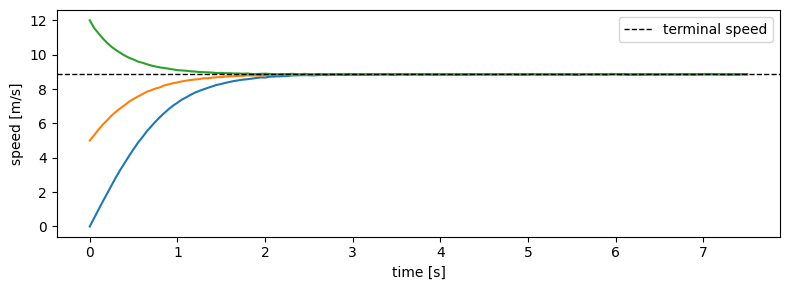

In [10]:
plt.figure(figsize=(8, 3))
for run in runs:
    plt.plot(np.arange(len(run["v"])) * dt, run["v"])
plt.axhline(
    np.sqrt(9.81 * m_value / true_c), ls="--", c="k", lw=1, label="terminal speed"
)
plt.xlabel("time [s]")
plt.ylabel("speed [m/s]")
plt.legend()
plt.tight_layout()

## Reading, freezing and sharing values

| Attribute | Holds |
|---|---|
| `.value` | the value it was declared with, which training does not change |
| `.value_numpy` | its current value, after the build |
| `.param` (`.constant` for a Constant) | the Keras variable, after the build: `.assign(...)` sets it |
| `.trainable` | whether training changes it |

A `Parameter` is frozen with `.freeze()` - or created frozen with
`trainable=False` - and released with `.unfreeze()`. The model also freezes them
by name, `model.freeze("drag")`. A frozen parameter, like a `Constant`, keeps
its value; unlike a `Constant`, it can be released later.

In [11]:
print("declared:", drag.value, " current:", drag.value_numpy)
drag.freeze()
fall.parameters  # the trainable column says no

declared: [1.]  current: [0.24952027]


┏━━━━━━━┳━━━━━━━━━━━┳━━━━━┳━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┓
┃ index ┃ parameter ┃ seq ┃ tw   ┃ dim  ┃ values ┃ trainable ┃
┡━━━━━━━╇━━━━━━━━━━━╇━━━━━╇━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━━━━┩
│ 0     │ drag      │ ()  │ None │ (1,) │ 1      │ no        │
├───────┼───────────┼─────┼──────┼──────┼────────┼───────────┤
│       │ total     │     │      │      │ 1      │ 0         │
└───────┴───────────┴─────┴──────┴──────┴────────┴───────────┘

In [12]:
drag.param.assign(np.array([0.3], "float32"))  # set it by hand
print("assigned:", drag.value_numpy)
drag.unfreeze()
print("trainable again:", drag.trainable)

assigned: [0.3]
trainable again: True


A parameter is **one** object: used in several places - several layers, several
models - it is one value, trained by all of them and frozen everywhere at once.
Two parameters with the same name are two values. To share a weight, share the
object:

In [13]:
k = Parameter("k", value=2.0)
a, b = Input("a", tw=1), Input("b", tw=1)
shared = Modely(
    "shared", inputs=[a, b], outputs=[Output("sa", k * a), Output("sb", k * b)]
).build()
shared.parameters  # one k, read twice

┏━━━━━━━┳━━━━━━━━━━━┳━━━━━┳━━━━━━┳━━━━━━┳━━━━━━━━┳━━━━━━━━━━━┓
┃ index ┃ parameter ┃ seq ┃ tw   ┃ dim  ┃ values ┃ trainable ┃
┡━━━━━━━╇━━━━━━━━━━━╇━━━━━╇━━━━━━╇━━━━━━╇━━━━━━━━╇━━━━━━━━━━━┩
│ 0     │ k         │ ()  │ None │ (1,) │ 1      │ yes       │
├───────┼───────────┼─────┼──────┼──────┼────────┼───────────┤
│       │ total     │     │      │      │ 1      │ 1         │
└───────┴───────────┴─────┴──────┴──────┴────────┴───────────┘

`Parameter`s also make the weights of layers: `Fir(kernel=Parameter(...))`
gives a filter known coefficients, or shares them between filters - see
[Fir and Linear](08_fir_linear.ipynb).

## Summary

| Task | Code |
|---|---|
| A known value | `Constant("g", value=9.81)`, or a number in an expression |
| A value to learn | `Parameter("c", value=guess)`, or `Parameter("w", dim=4)` drawn at random |
| Its shape | `seq=`, `tw=`, `dim=`, as an `Input`: `Parameter("w", tw=4, dim=3)` |
| Its value | a flat list (row-major) or an array of the declared sizes, in any order |
| Read it | `.value` (declared), `.value_numpy` (current), `.param` |
| Fix it | `p.freeze()`, `Parameter(..., trainable=False)`, `model.freeze("name")` |
| Share it | use the same object |

Next: [Partitioning](07_partitioning.ipynb).